# 47. Preconditioners, Orthogonalized Optimizers and Low Precision
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Optimizers on an ill-conditioned matrix regression: $\min_W\frac12\mathbb E\,(Wx-y)^{T}\Sigma_o(Wx-y)$ for $W\in\R^{32\times32}$, with input covariance $\Sigma_x$ and output weighting $\Sigma_o$ both rotated and of condition number $100$, so the Hessian $\Sigma_x\otimes\Sigma_o$ has condition number $10^4$; minibatches of $64$, linearly decaying learning rates, each method's rate tuned over a small grid. SGD with momentum and Adam stall well above the noise floor; the two-sided preconditioners (Shampoo, and K-FAC with the exact output curvature) reach it far sooner; Muon, whose orthogonalized steps have a size fixed by the learning rate, makes steady progress and overtakes the first-order methods as the rate decays.

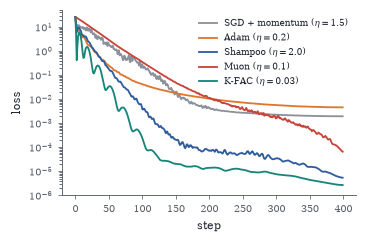

In [2]:
rng = np.random.default_rng(0); n = 32
def rot_spec(k): Qr, _ = np.linalg.qr(rng.normal(size=(n, n))); return (Qr * np.geomspace(1, 1 / k, n)) @ Qr.T
Sx = rot_spec(100); So = rot_spec(100); Lx = np.linalg.cholesky(Sx); Wst = rng.normal(size=(n, n))
def full_loss(Wm): Dm = Wm - Wst; return 0.5 * np.trace(So @ Dm @ Sx @ Dm.T)
def ns5(Gm):
    X = Gm / (np.linalg.norm(Gm) + 1e-7)
    for _ in range(5): Am = X @ X.T; X = 3.4445 * X + (-4.7750 * Am + 2.0315 * Am @ Am) @ X
    return X
def mpow(Mm, p, eps): w, Vv = np.linalg.eigh(Mm); return (Vv * (np.maximum(w, 0) + eps) ** p) @ Vv.T
def run_opt(kind, lr, T=400, seed=1):
    g = np.random.default_rng(seed); Wm = np.zeros((n, n)); Mo = np.zeros_like(Wm); Vo = np.zeros_like(Wm); Lm = np.zeros((n, n)); Rm = np.zeros((n, n)); Am = np.eye(n) * 1e-3; out = []
    for t in range(1, T + 1):
        lt = lr * (1 - t / (T + 1)); x = Lx @ g.normal(size=(n, 64)); y = Wst @ x + 0.01 * g.normal(size=(n, 64)); Gm = So @ (Wm @ x - y) @ x.T / 64; out.append(full_loss(Wm))
        if kind == "SGD + momentum": Mo = 0.9 * Mo + Gm; Wm = Wm - lt * Mo
        elif kind == "Adam": Mo = 0.9 * Mo + 0.1 * Gm; Vo = 0.999 * Vo + 0.001 * Gm**2; Wm = Wm - lt * (Mo / (1 - 0.9**t)) / (np.sqrt(Vo / (1 - 0.999**t)) + 1e-8)
        elif kind == "Shampoo":
            Lm += Gm @ Gm.T; Rm += Gm.T @ Gm; Mo = 0.9 * Mo + Gm
            if t % 5 == 1 or t < 10: Li, Ri = mpow(Lm, -0.25, 1e-6), mpow(Rm, -0.25, 1e-6)
            Wm = Wm - lt * Li @ Mo @ Ri
        elif kind == "Muon": Mo = 0.9 * Mo + Gm; Wm = Wm - lt * ns5(Mo)
        else:
            Am = 0.95 * Am + 0.05 * x @ x.T / 64; Mo = 0.9 * Mo + Gm
            if t % 5 == 1 or t < 10: Ai = np.linalg.inv(Am + 1e-3 * np.trace(Am) / n * np.eye(n)); Si = np.linalg.inv(So)
            Wm = Wm - lt * Si @ Mo @ Ai
    return np.array(out)
grids = {"SGD + momentum": [0.3, 0.6, 1.0, 1.5], "Adam": [0.03, 0.06, 0.1, 0.2], "Shampoo": [0.3, 1.0, 2.0], "Muon": [0.05, 0.1, 0.2], "K-FAC": [0.03, 0.1, 0.2]}
fig, ax = plt.subplots(figsize=(W * 0.7, 2.1))
for (kind, lrs), c in zip(grids.items(), [GRAY, ORANGE, BLUE, RED, TEAL]):
    best = min(lrs, key=lambda lr: np.nan_to_num(run_opt(kind, lr)[-20:].mean(), nan=1e300)); ax.semilogy(run_opt(kind, best), color=c, label=f"{kind} ($\\eta={best}$)")
ax.set_ylim(1e-6, 50); ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.legend(fontsize=5.8, frameon=False, loc="upper right")

In [3]:
rng = np.random.default_rng(0); x = rng.uniform(0, 1, 100000).astype(np.float16); exact = np.sum(x.astype(np.float64))
s = np.float16(0)
for v in x: s = np.float16(s + v)
def pairwise(a): return a[0] if len(a) == 1 else np.float16(pairwise(a[: len(a) // 2]) + pairwise(a[len(a) // 2:]))
print(f"exact {exact:.1f}   FP16 left-to-right {float(s):.1f}   FP16 pairwise {float(pairwise(x)):.1f}   FP16 values, FP32 accumulator {float(np.sum(x, dtype=np.float32)):.1f}")

exact 49957.5   FP16 left-to-right 2048.0   FP16 pairwise 49952.0   FP16 values, FP32 accumulator 49957.5


Rounding in BF16. Left: adding the increment $10^{-3}$ to the number $1$ ten thousand times: in FP32 the result grows to $11$; in BF16 with round-to-nearest it never moves, because the increment is less than half the spacing ($2^{-7}$) of BF16 numbers near $1$; with stochastic rounding it follows the exact sum, with small random deviations. Right: gradient descent on a least squares problem with the weights stored in BF16: round-to-nearest stagnates as soon as the updates become smaller than half a spacing, while stochastic rounding keeps making progress and ends within about an order of magnitude of FP32, the remaining gap being the random rounding noise in the stored weights.

Text(0, 0.5, 'training loss')

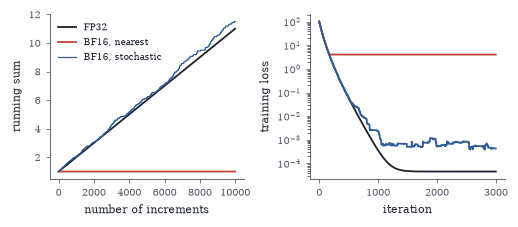

In [4]:
def bf16(x, rng=None):
    b = np.asarray(x, dtype=np.float32).view(np.uint32).astype(np.uint64)
    b = b + (0x7FFF + ((b >> 16) & 1) if rng is None else rng.integers(0, 1 << 16, size=b.shape, dtype=np.uint64))
    return (b & 0xFFFF0000).astype(np.uint32).view(np.float32)
rng = np.random.default_rng(0); K = 10000; a32 = np.float32(1); arn = bf16(np.float32(1)); asr = arn.copy(); t32, trn, tsr = [], [], []
for k in range(K): a32 = np.float32(a32 + 1e-3); arn = bf16(arn + np.float32(1e-3)); asr = bf16(asr + np.float32(1e-3), rng); t32.append(a32); trn.append(float(arn)); tsr.append(float(asr))
fig, axs = plt.subplots(1, 2, figsize=(W, 1.95)); axs[0].plot(t32, color=INK, label="FP32"); axs[0].plot(trn, color=RED, label="BF16, nearest"); axs[0].plot(tsr, color=BLUE, lw=0.8, label="BF16, stochastic")
axs[0].set_xlabel("number of increments"); axs[0].set_ylabel("running sum"); axs[0].legend(fontsize=6, frameon=False)
Xd = rng.normal(size=(200, 20)); wst = rng.normal(size=20) * 3; yd = Xd @ wst + 0.01 * rng.normal(size=200)
for mode, c in [("fp32", INK), ("rn", RED), ("sr", BLUE)]:
    w = np.zeros(20, dtype=np.float32); ls = []
    for t in range(3000):
        gr = Xd.T @ (Xd @ w - yd) / 200; wn = (w - 0.01 * gr).astype(np.float32)
        w = wn if mode == "fp32" else (bf16(wn) if mode == "rn" else bf16(wn, rng)); ls.append(0.5 * np.mean((Xd @ w - yd) ** 2))
    axs[1].semilogy(ls, color=c)
axs[1].set_xlabel("iteration"); axs[1].set_ylabel("training loss")

Outliers and rotations. Left: an activation vector in $\R^{1024}$ with four large outlier coordinates (red), and the same vector after a randomized Hadamard rotation (blue), whose entries are all of comparable size. Right: error of $4$-bit per-tensor quantization, relative to the norm of the non-outlier entries, as the outlier magnitude grows. Without rotation (red) the scale is set by the largest entry, and once the outliers exceed about $20$ every ordinary entry rounds to zero (error equal to the whole bulk). After rotation (blue) the scale is set by the overall norm spread over all coordinates, and the error grows far more slowly; only when the four outliers carry almost all of the energy (magnitudes in the hundreds) does the spread-out rounding error become larger still, which is why rotations are combined with finer, per-group scales in practice. The rotation is undone exactly after the matrix product, $Wx=(WQ^{T})(Qx)$.

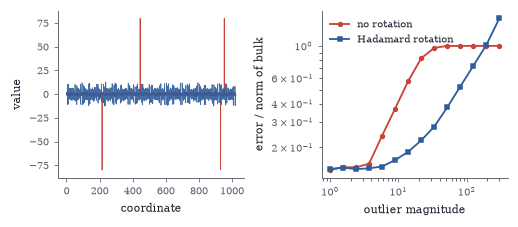

In [5]:
from scipy.linalg import hadamard
rng = np.random.default_rng(1); n = 1024; Hn = hadamard(n) / np.sqrt(n); Dg = rng.choice([-1.0, 1.0], n)
def q4(v): s = np.abs(v).max() / 7; return np.clip(np.round(v / s), -8, 7) * s
def make(mag): v = rng.normal(size=n); idx = rng.choice(n, 4, replace=False); v[idx] = mag * rng.choice([-1, 1], 4); return v, np.setdiff1d(np.arange(n), idx)
x, _ = make(80.0); xr = Hn @ (Dg * x)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.95)); axs[0].plot(x, color=RED, lw=0.5); axs[0].plot(xr, color=BLUE, lw=0.5, alpha=0.9); axs[0].set_xlabel("coordinate"); axs[0].set_ylabel("value")
mags = np.geomspace(1, 300, 14); e0, e1 = [], []
for mg in mags:
    a, b = [], []
    for _ in range(20):
        v, bulk = make(mg); vr = Hn @ (Dg * v); nb = np.linalg.norm(v[bulk]); a.append(np.linalg.norm(q4(v) - v) / nb); b.append(np.linalg.norm(Dg * (Hn.T @ q4(vr)) - v) / nb)
    e0.append(np.mean(a)); e1.append(np.mean(b))
axs[1].loglog(mags, e0, "o-", color=RED, ms=2.5, label="no rotation"); axs[1].loglog(mags, e1, "s-", color=BLUE, ms=2.5, label="Hadamard rotation"); axs[1].set_xlabel("outlier magnitude"); axs[1].set_ylabel("error / norm of bulk"); axs[1].legend(fontsize=6.3, frameon=False)

In [6]:
from scipy.linalg import cholesky
rng = np.random.default_rng(0); n, m, Nn = 128, 64, 1024; Qr, _ = np.linalg.qr(rng.normal(size=(n, n))); X = (Qr * np.sqrt(np.geomspace(1, 0.01, n))) @ rng.normal(size=(n, Nn)); Wt = rng.normal(size=(m, n))
def quant(w, s): return np.clip(np.round(w / s), -8, 7) * s
s = np.abs(Wt).max(1, keepdims=True) / 7; Wrtn = quant(Wt, s)
H = X @ X.T + 1e-2 * np.trace(X @ X.T) / n * np.eye(n); U = cholesky(np.linalg.inv(H), lower=False); Wq = Wt.copy(); Wg = np.zeros_like(Wt)
for j in range(n):
    qj = quant(Wq[:, j:j + 1], s)[:, 0]; Wg[:, j] = qj; err = (Wq[:, j] - qj) / U[j, j]; Wq[:, j + 1:] -= np.outer(err, U[j, j + 1:])
rel = lambda Wh: np.linalg.norm((Wh - Wt) @ X) / np.linalg.norm(Wt @ X)
print(f"4-bit, round to nearest: output error {rel(Wrtn):.4f}     4-bit with GPTQ compensation: {rel(Wg):.4f}")

4-bit, round to nearest: output error 0.1115     4-bit with GPTQ compensation: 0.0796


In [7]:
rng = np.random.default_rng(0); X = rng.normal(size=(10, 200)) * np.geomspace(1, 0.01, 10)[:, None]; Y = rng.normal(size=(5, 10)) @ X + 0.1 * rng.normal(size=(5, 200)); Wm = rng.normal(size=(5, 10))
G = (Wm @ X - Y) @ X.T / 200; A = X @ X.T / 200; Wn = Wm - G @ np.linalg.inv(A); Wls = Y @ X.T @ np.linalg.inv(X @ X.T)
print("one K-FAC step reaches least squares:", np.allclose(Wn, Wls), "   condition number of A:", f"{np.linalg.cond(A):.1e}")

one K-FAC step reaches least squares: True    condition number of A: 9.1e+03


In [8]:
rng = np.random.default_rng(1); n = 6; B1, B2 = rng.normal(size=(n, n)), rng.normal(size=(n, n)); A = B1 @ B1.T + np.eye(n); S = B2 @ B2.T + np.eye(n); G = rng.normal(size=(n, n))
lhs = np.linalg.solve(np.kron(A, S), G.flatten(order="F")); rhs = (np.linalg.solve(S, G) @ np.linalg.inv(A)).flatten(order="F")
print("max difference:", np.abs(lhs - rhs).max())

max difference: 2.7755575615628914e-16


In [9]:
rng = np.random.default_rng(2); G = rng.normal(size=(8, 5)); U, s, Vt = np.linalg.svd(G, full_matrices=False)
def proot(Mm, p): w, Q = np.linalg.eigh(Mm); w = np.where(w > 1e-10, w, 0); wp = np.zeros_like(w); wp[w > 0] = w[w > 0] ** p; return (Q * wp) @ Q.T
sh = proot(G @ G.T, -0.25) @ G @ proot(G.T @ G, -0.25); X = G / np.linalg.norm(G)
for _ in range(5): Am = X @ X.T; X = 3.4445 * X + (-4.7750 * Am + 2.0315 * Am @ Am) @ X
print("Shampoo one-step = UV^T:", np.allclose(sh, U @ Vt), "   singular values after 5 quintic steps:", np.round(np.linalg.svd(X, compute_uv=False), 3))

Shampoo one-step = UV^T: True    singular values after 5 quintic steps: [1.081 1.081 0.735 0.706 0.705]


In [10]:
rng = np.random.default_rng(3); G = rng.normal(size=(6, 3)) @ rng.normal(size=(3, 5)); v = G.flatten(order="F")
def sqrtm_psd(Mm): w, Q = np.linalg.eigh(Mm); return (Q * np.sqrt(np.maximum(w, 0))) @ Q.T
K = np.kron(sqrtm_psd(G.T @ G), sqrtm_psd(G @ G.T))
for c in (3, 2.5, 1): print(f"c={c}: smallest eigenvalue of c K - vv^T = {np.linalg.eigvalsh(c * K - np.outer(v, v)).min():+.3e}")
U, s, Vt = np.linalg.svd(G); Ge = U[:, :3] @ Vt[:3]; ve = Ge.flatten(order="F"); Ke = np.kron(sqrtm_psd(Ge.T @ Ge), sqrtm_psd(Ge @ Ge.T))
print("equal singular values, c=3:", f"{np.linalg.eigvalsh(3 * Ke - np.outer(ve, ve)).min():+.2e}", "  c=2.99:", f"{np.linalg.eigvalsh(2.99 * Ke - np.outer(ve, ve)).min():+.2e}")

c=3: smallest eigenvalue of c K - vv^T = -3.854e-14
c=2.5: smallest eigenvalue of c K - vv^T = -6.228e+00
c=1: smallest eigenvalue of c K - vv^T = -4.646e+01
equal singular values, c=3: -8.31e-16   c=2.99: -1.00e-02


In [11]:
print("FP16 spacing at 1:", np.spacing(np.float16(1)), "   1 + 4.8e-4 in FP16:", np.float16(1) + np.float16(4.8e-4), "   1 + 5e-4:", np.float16(1) + np.float16(5e-4))

FP16 spacing at 1: 0.000977    1 + 4.8e-4 in FP16: 1.0    1 + 5e-4: 1.001


In [12]:
rng = np.random.default_rng(4); x = np.full(100000, 1 + 0.3 * 2.0**-7, dtype=np.float32)
b = x.view(np.uint32).astype(np.uint64) + rng.integers(0, 1 << 16, size=x.shape, dtype=np.uint64); r = (b & 0xFFFF0000).astype(np.uint32).view(np.float32).astype(np.float64)
print(f"mean - x = {r.mean() - float(x[0]):+.2e}   variance {r.var():.3e}  (predicted {0.21 * 2.0**-14:.3e})   fraction rounded up {np.mean(r > 1):.4f}")

mean - x = +7.55e-06   variance 1.284e-05  (predicted 1.282e-05)   fraction rounded up 0.3010


In [13]:
from scipy.linalg import hadamard
def fwht(x):
    x = x.copy(); h = 1
    while h < len(x):
        x = x.reshape(-1, 2, h); x = np.stack([x[:, 0] + x[:, 1], x[:, 0] - x[:, 1]], 1).reshape(-1); h *= 2
    return x
rng = np.random.default_rng(5); xv = rng.normal(size=1024); print("max difference from dense product:", np.abs(fwht(xv) - hadamard(1024) @ xv).max())

max difference from dense product: 9.947598300641403e-14


In [14]:
rng = np.random.default_rng(6); B = rng.normal(size=(6, 6)); H = B @ B.T + np.eye(6); q, c = 2, 0.37; Hi = np.linalg.inv(H)
d = c / Hi[q, q] * Hi[q]; K = np.block([[2 * H, np.eye(6)[:, [q]]], [np.eye(6)[[q]], np.zeros((1, 1))]]); d2 = np.linalg.solve(K, np.r_[np.zeros(6), c])[:6]
print("formula equals KKT solution:", np.allclose(d, d2), "   value", round(d @ H @ d, 6), " vs c^2/(H^-1)_qq =", round(c * c / Hi[q, q], 6))

formula equals KKT solution: True    value 0.778968  vs c^2/(H^-1)_qq = 0.778968
